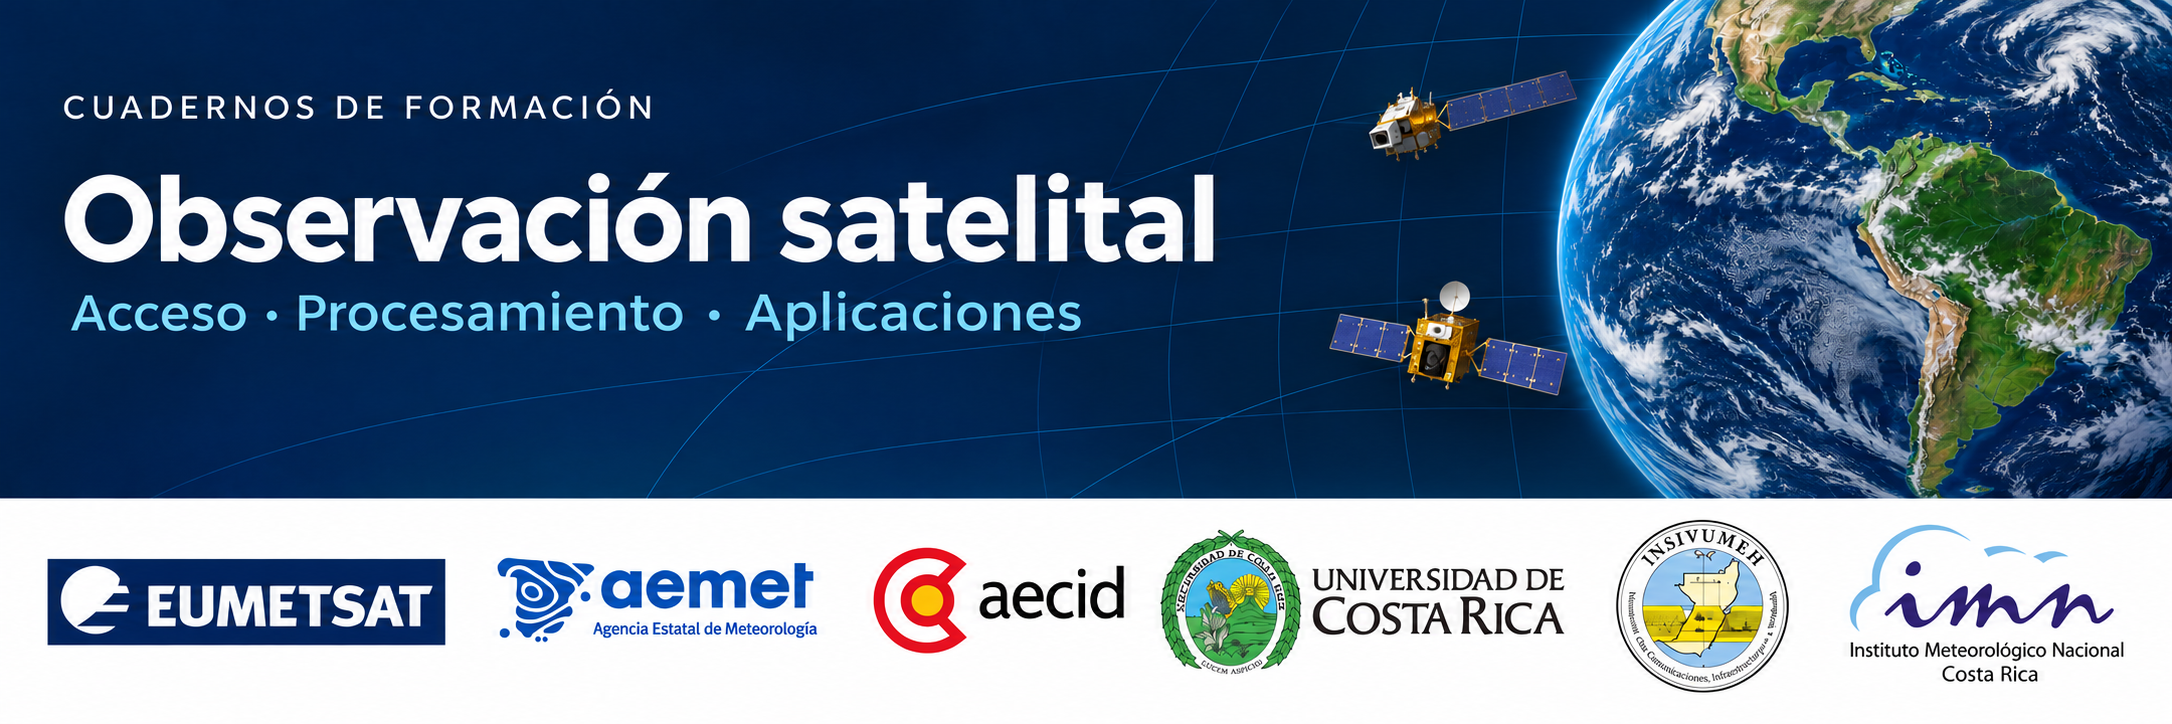

**PRODUCTOS Y APLICACIONES DE LOS SATÉLITES METEOROLÓGICOS**  
Fase presencial · Uruguay · Noviembre de 2026  
AEMET y EUMETSAT, con apoyo de AECID

# 01 · SST · Acceso a datos de EUMETSAT

*Temperatura superficial del mar frente a Uruguay y el sur de Brasil*

| Ficha de la práctica | Detalle |
| :--- | :--- |
| Área temática | Océano |
| Datos y acceso | OSI SAF · Metop/AVHRR · EUMDAC |
| Entorno | Google Colab y Google Drive |

> **Guía de trabajo:** lea el caso y sus requisitos; ejecute las celdas en orden; revise cada resultado antes de avanzar. Después, cambie un parámetro a la vez y conserve la procedencia de los datos.

**Recorrido:** comprender el caso · preparar el acceso · procesar · interpretar · guardar y reutilizar.

---


## Antes de comenzar · cuentas y acceso

**Para este cuaderno:** EUMETSAT para nuevas descargas; el respaldo incluido y la caché válida no requieren autenticarse otra vez.

| Cuenta o servicio | Cuándo la necesita | Registro |
| :--- | :--- | :--- |
| Google | Sí, para ejecutar esta práctica en Colab y guardar los resultados en su Drive. | [Crear cuenta de Google](https://accounts.google.com/signup) |
| EUMETSAT | EUMETSAT para nuevas descargas; el respaldo incluido y la caché válida no requieren autenticarse otra vez. | [Crear cuenta](https://user.eumetsat.int/register) |

**Crear una cuenta es un proceso guiado y sencillo.** Si ya utiliza Gmail o Google Drive, puede usar esa misma cuenta de Google. También puede crearla con un correo que ya tenga, sin abrir un Gmail nuevo: [guía en español](https://support.google.com/accounts/answer/27441?hl=es).

Después de crear la cuenta, entre en [API Key Management](https://api.eumetsat.int/api-key/) con el usuario y la contraseña del portal. Este cuaderno solicita **Consumer Key** y **Consumer Secret** en campos ocultos; no son el usuario y la contraseña del portal.

Antes de la sesión, compruebe que puede iniciar sesión y complete la verificación por correo si el portal la solicita. Cada participante utiliza su propia cuenta. Introduzca las credenciales únicamente cuando el cuaderno lo indique; no las escriba en celdas que vaya a compartir.

---


## Presentación del caso

### Bienvenidas y bienvenidos

Los datos satelitales adquieren valor cuando podemos **acceder a ellos, evaluar su calidad y volver a
utilizarlos**. En esta práctica recorreremos ese proceso con un producto real de temperatura superficial
del mar, conocida como **SST** por sus siglas en inglés (*Sea Surface Temperature*).

Trabajaremos con una composición de **Metop/AVHRR**, distribuida por EUMETSAT a través de OSI SAF.
Exploraremos las aguas próximas a Uruguay y al sur de Brasil, conservando los valores científicos,
las coordenadas y las banderas de calidad del archivo original. Cada participante guardará sus propios
datos y resultados en Google Drive para poder retomar y adaptar el ejercicio en su institución.

**Al terminar esta práctica, usted podrá:**

1. Localizar un producto en el catálogo de EUMETSAT y descargar una composición mediante EUMDAC.
2. Distinguir la temperatura, la calidad de cada píxel y la cobertura temporal del producto.
3. Crear un mapa georreferenciado y reutilizar los datos guardados sin repetir la descarga.

> **Nuestro punto de partida:** un producto, una fecha y una región.
> Primero completamos y comprendemos este caso; luego cambiamos un parámetro a la vez.

| Nuestro caso de estudio | Selección inicial |
|---|---|
| Variable | Temperatura superficial del mar, SST *subskin* |
| Producto | OSI SAF Global L3C AVHRR SST — Metop |
| Región | Uruguay, sur de Brasil y aguas adyacentes |
| Fecha y referencia | 15 de noviembre de 2026 · 12 UTC |
| Malla | 0,05° de latitud y longitud |
| Calidad inicial | QL 4 y 5: aceptable y mejor calidad |
| Resultados | NetCDF original, recorte regional, mapa, tabla de calidad y registro de procedencia |

**Antes de comenzar:** necesita una cuenta de Google con acceso a Colab y Drive, y una cuenta de
EUMETSAT. En la sección 5 encontrará cómo iniciar sesión en el portal y obtener las claves de EUMDAC.
No necesita instalar programas en su computadora ni utilizar una GPU.

**Una organización pensada para la conexión del taller.** El archivo global de este caso, de unos
36 MB, viaja de EUMETSAT al servidor de Colab y se guarda en su Drive. La conexión del aula se utiliza
para abrir el cuaderno, autorizar las cuentas y mostrar las salidas. Una copia regional incluida permite
continuar si falla el acceso a EUMETSAT. **Colab sigue necesitando internet**; las sesiones son temporales,
pero los archivos guardados en Drive permanecen.

**Esta práctica es independiente.** Todos sus archivos quedan en
`Mi unidad/Taller_Uruguay/SST_EUMETSAT/`. Los otros productos del taller tendrán sus propios cuadernos y carpetas.

La colección utilizada es `EO:EUM:DAT:METOP:GLB-SST-NC`. Ofrece dos composiciones por día de SST
*subskin* (subsuperficial inmediata). La referencia 12 UTC representa una composición de aproximadamente
12 horas; no una observación instantánea ni necesariamente nocturna. El tiempo de cada píxel se obtiene
de `time + sst_dtime`.

**Para empezar:** abra este archivo en [Google Colab](https://colab.research.google.com/),
**Archivo → Subir cuaderno**, y ejecute las celdas en orden. Lea el resultado de cada paso antes de avanzar.

*Instructor: Dr. Marcial Garbanzo Salas · Universidad de Costa Rica*


---

## 1 · Preparar el entorno

La instalación ocurre en Colab, no en la computadora del participante. Se fija EUMDAC 3.1.1,
la versión utilizada para verificar este ejercicio. No hace falta Anaconda ni una GPU.


In [ ]:
import sys, subprocess
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
                       'eumdac==3.1.1', 'xarray', 'netCDF4', 'matplotlib', 'cartopy', 'pandas'])
print('Entorno preparado.')

---

## 2 · Conectar su propio Google Drive

Cada participante autoriza **su propia cuenta de Google** mediante la ventana que abre Colab.
Revise la solicitud y seleccione su cuenta. No escriba la contraseña de Google en el código.
Este cuaderno utiliza únicamente `Mi unidad/Taller_Uruguay/SST_EUMETSAT` para sus archivos.
El montaje concede al entorno acceso a Drive: use una copia de confianza del cuaderno.

Se guardan el original, el recorte, la cartografía y los resultados. **Las credenciales de EUMETSAT
se introducen con campos ocultos y no se guardan en Drive ni en el archivo del cuaderno.**


In [ ]:
from pathlib import Path
from google.colab import drive
drive.mount('/content/drive')
RAIZ = Path('/content/drive/MyDrive/Taller_Uruguay/SST_EUMETSAT')
for nombre in ['originales', 'regiones', 'resultados', 'cartografia']:
    (RAIZ / nombre).mkdir(parents=True, exist_ok=True)
print('Carpeta de trabajo:', RAIZ)

---

## 3 · Elegir el caso

La primera ejecución usa **En línea**: busca el producto en EUMETSAT y descarga el original.
Las siguientes reutilizan los archivos verificados en Drive, sin repetir la descarga.

Mantenga el caso inicial para la primera prueba. Después podrá cambiar **una sola cosa**: la fecha,
la región o el umbral de calidad. Los límites son longitudes y latitudes en grados; oeste y sur negativos.
El cuaderno no admite regiones que crucen el antimeridiano.

El **Respaldo incluido** contiene exactamente la región, fecha y hora iniciales: nunca sustituye
silenciosamente otra fecha o región. Es una copia real del mismo producto, no datos simulados.
Incluye el recorte y su procedencia; el archivo global se obtiene mediante el modo En línea.


In [ ]:
#@title Parámetros de esta práctica
FECHA = '2026-11-15' #@param {type:"date"}
HORA_UTC = 12 #@param [0,12] {type:"raw"}
OESTE = -60.0 #@param {type:"number"}
ESTE = -45.0 #@param {type:"number"}
SUR = -42.0 #@param {type:"number"}
NORTE = -28.0 #@param {type:"number"}
CALIDAD_MINIMA = 4 #@param [3,4,5] {type:"raw"}
MODO = 'En línea' #@param ["En línea","Respaldo incluido"]

from datetime import datetime
datetime.strptime(FECHA, '%Y-%m-%d')
assert HORA_UTC in (0,12), 'La hora debe ser 0 o 12 UTC.'
assert -180 <= OESTE < ESTE <= 180 and -90 <= SUR < NORTE <= 90, 'Revise los límites.'
assert CALIDAD_MINIMA in (3,4,5)
assert (ESTE-OESTE)*(NORTE-SUR) <= 600, 'Para esta práctica, elija una región más pequeña (máximo 600 grados cuadrados).'
CAJA = [float(OESTE), float(SUR), float(ESTE), float(NORTE)]
print(FECHA, f'{HORA_UTC:02d}:00 UTC', '· región O,S,E,N:', CAJA, '· QL >=', CALIDAD_MINIMA)

---

## 4 · Preparar el acceso y el respaldo

Esta celda contiene las funciones de descarga y verificación, además de un pequeño respaldo regional
y costas de Natural Earth. Puede abrir el código para inspeccionarlo. No contiene contraseñas ni tokens.
Las coordenadas, unidades y banderas provienen del NetCDF original: no se reconstruyen desde una imagen.


In [ ]:
#@title Preparar funciones, cartografía y respaldo (ejecutar una vez)
import base64, hashlib, io, json, shutil, zipfile, time
from datetime import datetime, timezone
from getpass import getpass
import eumdac
import numpy as np
import pandas as pd
import xarray as xr
from IPython.display import display

COLECCION = 'EO:EUM:DAT:METOP:GLB-SST-NC'
ID_PRODUCTO = f"S-OSI_-FRA_-MTOP-GLBSST_FIELD-{FECHA.replace('-','')}{int(HORA_UTC):02d}00Z"
REFERENCIA = np.datetime64(f'{FECHA}T{HORA_UTC:02d}:00:00')
clave_region = hashlib.sha256(json.dumps(CAJA).encode()).hexdigest()[:12]
RUTA_ORIGINAL = RAIZ/'originales'/f'{ID_PRODUCTO}.nc'
RUTA_REGION = RAIZ/'regiones'/f'{ID_PRODUCTO}_{clave_region}.nc'
RUTA_FICHA = RUTA_REGION.with_suffix('.json')
RUTA_CATALOGO = RUTA_ORIGINAL.with_suffix('.json')
TRABAJO = Path('/content/sst_trabajo')
TRABAJO.mkdir(parents=True, exist_ok=True)
REQUERIDAS = ['sea_surface_temperature','quality_level','l2p_flags','sst_dtime']

def sha256(ruta):
    h=hashlib.sha256()
    with open(ruta,'rb') as f:
        for bloque in iter(lambda:f.read(1024*1024),b''): h.update(bloque)
    return h.hexdigest()

def escribir_json(ruta, contenido):
    temporal = ruta.with_suffix(ruta.suffix+'.part')
    temporal.write_text(json.dumps(contenido,indent=2,ensure_ascii=False),encoding='utf-8')
    temporal.replace(ruta)

def guardar_archivo(origen,destino):
    temporal=destino.with_suffix(destino.suffix+'.part')
    shutil.copyfile(origen,temporal)
    if sha256(origen)!=sha256(temporal):
        raise RuntimeError('La copia no coincide. Vuelva a ejecutar esta celda.')
    temporal.replace(destino)

def validar(ruta, regional=False):
    with xr.open_dataset(ruta, decode_timedelta=False) as d:
        if not all(v in d for v in REQUERIDAS): raise ValueError('Faltan variables SST/QA/tiempo.')
        if d.lat.ndim != 1 or d.lon.ndim != 1: raise ValueError('Se esperaba la malla regular del producto GLB SST.')
        if d.sizes.get('time') != 1 or np.datetime64(d.time.values[0],'s') != REFERENCIA:
            raise ValueError('La fecha/hora del archivo no coincide con la solicitada.')
        if d.sea_surface_temperature.attrs.get('units','').lower() not in ('k','kelvin'):
            raise ValueError('No se reconocen las unidades SST. No se convierte por suposición.')
        for coord in ['lat','lon']:
            v=d[coord].values
            if len(v)<2 or not np.all(np.isfinite(v)) or not np.all(np.diff(v)>0):
                raise ValueError('Coordenadas inválidas o no crecientes.')
        if regional:
            saved=json.loads(d.attrs.get('subset_bbox_wsen','[]'))
            if saved!=CAJA: raise ValueError('El recorte no corresponde a esta región.')

def region_en_cache():
    if not (RUTA_REGION.exists() and RUTA_FICHA.exists()): return False
    try:
        ficha=json.loads(RUTA_FICHA.read_text(encoding='utf-8'))
        if ficha['product']!=ID_PRODUCTO or ficha['bbox_wsen']!=CAJA: return False
        if sha256(RUTA_REGION)!=ficha['regional_sha256']: return False
        validar(RUTA_REGION,regional=True)
        return True
    except (ValueError, OSError, KeyError):
        return False

def original_en_cache():
    hashfile=RUTA_ORIGINAL.with_suffix('.sha256')
    if not (RUTA_ORIGINAL.exists() and hashfile.exists()): return False
    if sha256(RUTA_ORIGINAL)!=hashfile.read_text().strip(): return False
    try:
        validar(RUTA_ORIGINAL)
        return True
    except (ValueError,OSError):
        return False

def conectar():
    print('Copie Consumer Key y Consumer Secret de https://api.eumetsat.int/api-key')
    key=getpass('Consumer Key (oculta): ').strip()
    secret=getpass('Consumer Secret (oculta): ').strip()
    try:
        token=eumdac.AccessToken((key,secret))
        str(token)  # Solicita un token sin mostrarlo.
    except Exception:
        raise RuntimeError('No se pudo autenticar. Revise las claves API y la conexión. La contraseña del portal no es el Consumer Secret.') from None
    finally:
        del key, secret
    print('Autenticación correcta. Credenciales solo en la memoria de esta sesión.')
    return eumdac.DataStore(token)

def descargar_un_producto(datastore):
    coleccion=datastore.get_collection(COLECCION)
    inicio=datetime.strptime(FECHA,'%Y-%m-%d')
    final=inicio.replace(hour=23,minute=59,second=59)
    try:
        # Una comprensión evita una consulta extra de conteo que list(...) puede activar.
        candidatos=[p for p in coleccion.search(dtstart=inicio,dtend=final)]
        print('Resultados del catálogo (intervalos que se solapan con el día):')
        for p in candidatos: print(' ',str(p))
        seleccionados=[p for p in candidatos if str(p)==ID_PRODUCTO]
        if len(seleccionados)!=1:
            raise ValueError('No se encontró exactamente el producto solicitado.')
        p=seleccionados[0]
        entradas=[e for e in p.entries if e.lower().endswith('.nc')]
        if len(entradas)!=1: raise ValueError('No se encontró una única entrada NetCDF.')
        print('Seleccionado:',str(p))
        destino=TRABAJO/(ID_PRODUCTO+'.nc.part')
        n=0; siguiente=8*1024*1024
        with p.open(entry=entradas[0]) as origen, destino.open('wb') as f:
            while True:
                bloque=origen.read(1024*1024)
                if not bloque: break
                f.write(bloque); n+=len(bloque)
                if n>=siguiente:
                    print(f'  {n/1e6:.1f} MB recibidos en Colab',flush=True)
                    siguiente+=8*1024*1024
        validar(destino)
        guardar_archivo(destino,RUTA_ORIGINAL)
        RUTA_ORIGINAL.with_suffix('.sha256').write_text(sha256(RUTA_ORIGINAL))
        escribir_json(RUTA_CATALOGO,p.metadata)
        print(f'Original guardado en Drive: {RUTA_ORIGINAL.stat().st_size/1e6:.2f} MB')
    except Exception as exc:
        if isinstance(exc,ValueError): print(str(exc))
        raise RuntimeError('No se completó la descarga. Revise la conexión y vuelva a intentar. Para el caso inicial puede seleccionar Respaldo incluido; no se sustituyen datos automáticamente.') from None

def recortar_original():
    # Abrir de forma diferida y seleccionar ANTES de cargar: la malla global decodificada ocupa varios GB.
    with xr.open_dataset(RUTA_ORIGINAL,decode_timedelta=False) as original:
        recorte=original.sel(lon=slice(OESTE,ESTE),lat=slice(SUR,NORTE)).load()
    if recorte.sizes['lat']<2 or recorte.sizes['lon']<2:
        raise ValueError('El recorte es vacío o demasiado pequeño.')
    recorte.attrs.update(parent_product=ID_PRODUCTO,parent_collection=COLECCION,
        subset_bbox_wsen=json.dumps(CAJA),
        northernmost_latitude=float(recorte.lat.max()),southernmost_latitude=float(recorte.lat.min()),
        westernmost_longitude=float(recorte.lon.min()),easternmost_longitude=float(recorte.lon.max()),
        history=recorte.attrs.get('history','')+'; regional subset, no resampling')
    temporal=TRABAJO/'region_nueva.nc'
    recorte.to_netcdf(temporal,encoding={v:{'zlib':True,'complevel':4} for v in recorte.data_vars})
    validar(temporal,regional=True)
    guardar_archivo(temporal,RUTA_REGION)
    ficha=dict(collection=COLECCION,product=ID_PRODUCTO,bbox_wsen=CAJA,
        reference_utc=f'{FECHA}T{HORA_UTC:02d}:00:00Z',
        original_bytes=RUTA_ORIGINAL.stat().st_size,original_sha256=sha256(RUTA_ORIGINAL),
        regional_sha256=sha256(RUTA_REGION),data_origin='descarga EUMETSAT; recorte en Colab sin remuestreo',
        extracted_utc=datetime.now(timezone.utc).isoformat())
    escribir_json(RUTA_FICHA,ficha)

def usar_respaldo():
    with zipfile.ZipFile(io.BytesIO(PAQUETE_BYTES)) as z:
        ficha=json.loads(z.read('procedencia.json'))
        if ficha['product']!=ID_PRODUCTO or ficha['bbox_wsen']!=CAJA:
            raise ValueError('El respaldo solo corresponde a 2026-11-15, 12 UTC y la región inicial O=-60, E=-45, S=-42, N=-28. Restaure esos parámetros y ejecute desde la sección 3.')
        datos=z.read('region.nc')
        if hashlib.sha256(datos).hexdigest()!=ficha['regional_sha256']:
            raise ValueError('El respaldo no superó la verificación de integridad.')
        temporal=TRABAJO/'respaldo.nc'; temporal.write_bytes(datos)
        validar(temporal,regional=True)
        guardar_archivo(temporal,RUTA_REGION)
        escribir_json(RUTA_FICHA,ficha)
        escribir_json(RUTA_CATALOGO,json.loads(z.read('catalogo.json')))

PAQUETE_B64 = '...'
PAQUETE_BYTES=base64.b64decode(PAQUETE_B64)
if hashlib.sha256(PAQUETE_BYTES).hexdigest()!='6f11bc910898f7765879db278eba896f990e72f0fc8380d0689b9e2c0eee598d':
    raise ValueError('El cuaderno fue alterado o quedó incompleto al copiarlo.')
with zipfile.ZipFile(io.BytesIO(PAQUETE_BYTES)) as z:
    for entrada in z.namelist():
        if entrada.startswith('costas/'):
            destino=RAIZ/'cartografia'/Path(entrada).name
            if not destino.exists(): destino.write_bytes(z.read(entrada))
print('Funciones listas. La cartografía está guardada en su Drive.')

---

## 5 · Autenticarse y obtener el dato

Abra [API Key de EUMETSAT](https://api.eumetsat.int/api-key) e **inicie sesión con su usuario y
contraseña del portal**. Copie los dos valores **Consumer Key** y **Consumer Secret** a los campos
ocultos que pedirá esta celda. Son las credenciales para EUMDAC; no son su usuario y contraseña.
No comparta claves ni use una misma cuenta para los 17 participantes.

Si ya hay un recorte verificado en su Drive, esta celda no pide claves ni descarga otra vez.
Para cambiar de región conserva el mismo original. Para una fecha/hora nueva necesita otro producto.
No se lanza un lote mensual: **solo se selecciona una composición**.


In [ ]:
usar_cache=region_en_cache()
if usar_cache and MODO == 'En línea':
    origen_guardado=json.loads(RUTA_FICHA.read_text(encoding='utf-8'))['data_origin']
    if origen_guardado.startswith('respaldo incluido'):
        print('Hay un respaldo guardado; ahora se solicitará el original a EUMETSAT.')
        usar_cache=False
if usar_cache:
    print('Se reutiliza el recorte verificado de Drive. No hubo descarga.')
elif MODO == 'Respaldo incluido':
    usar_respaldo()
    print('RESPALDO INCLUIDO: copia regional real del caso inicial; no hubo descarga en vivo.')
elif MODO == 'En línea':
    if original_en_cache():
        print('Se reutiliza el original verificado de Drive.')
    else:
        almacen=conectar()
        try:
            descargar_un_producto(almacen)
        finally:
            del almacen
    recortar_original()
else:
    raise ValueError('Modo no reconocido.')

procedencia=json.loads(RUTA_FICHA.read_text(encoding='utf-8'))
print('Procedencia:',procedencia['data_origin'])
print('Producto:',procedencia['product'])
print(f'Recorte guardado: {RUTA_REGION.stat().st_size/1e6:.3f} MB')
print('Archivo:',RUTA_REGION.name)

---

## 6 · Revisar el producto y aplicar calidad

La SST está en **kelvin**: para obtener °C se resta 273,15. Xarray ya aplica `scale_factor`,
`add_offset` y los valores faltantes del NetCDF; no vuelva a aplicar esos factores.

El archivo define QL 3 = baja calidad, QL 4 = aceptable y QL 5 = mejor calidad.
OSI SAF permite usar QL 3–5; esta práctica comienza con **QL ≥ 4**, una elección más exigente.
También se excluyen tierra, hielo y lagos mediante `l2p_flags`. Los huecos permanecen como huecos:
no se interpolan ni se reemplazan por cero.

El porcentaje mostrado se calcula sobre celdas oceánicas de la región (según esas banderas),
no sobre toda la caja. Una composición parcial no representa automáticamente toda la región.


In [ ]:
with xr.open_dataset(RUTA_REGION,decode_timedelta=False) as archivo:
    datos=archivo.load()
sst_k=datos.sea_surface_temperature.isel(time=0)
calidad=datos.quality_level.isel(time=0)
banderas=datos.l2p_flags.isel(time=0)
mascaras=dict(zip(banderas.attrs['flag_meanings'].split(),map(int,banderas.attrs['flag_masks'])))
excluir=mascaras['land'] | mascaras['ice'] | mascaras['lake']
oceano=np.isfinite(banderas) & ((banderas.fillna(0).astype('int32') & excluir)==0)
validos=oceano & np.isfinite(sst_k) & (calidad>=CALIDAD_MINIMA)
sst_c=(sst_k-273.15).where(validos)
sst_c.attrs={'long_name':'Temperatura superficial del mar (subskin)','units':'degree_Celsius'}
n_oceano=int(oceano.sum()); n_validos=int(validos.sum())
porcentaje=100*n_validos/n_oceano if n_oceano else float('nan')
tabla=pd.DataFrame([{'QL':q,'celdas_oceánicas_con_SST':int(((calidad==q)&oceano&np.isfinite(sst_k)).sum())}
                    for q in range(6)])
display(tabla)
print('Plataforma:',datos.attrs.get('platform'), '· Sensor:',datos.attrs.get('sensor'))
print('Nivel:',datos.attrs.get('processing_level'), '· Malla:',datos.attrs.get('spatial_resolution'))
print('Cobertura temporal del producto:',datos.attrs.get('time_coverage_start'),'→',datos.attrs.get('time_coverage_end'))
print(f'Celdas válidas: {n_validos:,} / {n_oceano:,} oceánicas ({porcentaje:.1f} %)')
if n_validos:
    print(f'Rango retenido: {float(sst_c.min()):.2f} a {float(sst_c.max()):.2f} °C')
else:
    print('No hay SST válida para este filtro. El mapa quedará sin datos; no reduzca el filtro sin justificarlo.')
display(datos[REQUERIDAS])

---

## 7 · Generar y guardar el mapa

El mapa usa coordenadas geográficas del archivo y una escala fija para este caso, **8–30 °C**.
La figura de alta resolución se guarda en Drive; la vista en el cuaderno es más pequeña para reducir tráfico.
Cambiar a una región tropical puede requerir ajustar la escala de colores de la celda, sin cambiar los datos.


In [ ]:
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.io.shapereader as shpreader
from IPython.display import Image, display

VMIN, VMAX = 8, 30
nombre=f'SST_{FECHA}_{HORA_UTC:02d}UTC_QL{CALIDAD_MINIMA}_{clave_region}'
mapa=RAIZ/'resultados'/(nombre+'.png')
fig=plt.figure(figsize=(10,7),facecolor='white')
ax=fig.add_subplot(111,projection=ccrs.PlateCarree())
ax.set_extent([OESTE,ESTE,SUR,NORTE],crs=ccrs.PlateCarree())
ax.set_facecolor('#e7ebef')
colores=plt.get_cmap('turbo').copy(); colores.set_bad('#e7ebef')
im=ax.pcolormesh(datos.lon,datos.lat,sst_c,transform=ccrs.PlateCarree(),
                 cmap=colores,vmin=VMIN,vmax=VMAX,shading='auto',rasterized=True)
lector=shpreader.Reader(str(RAIZ/'cartografia'/'ne_50m_coastline.shp'))
ax.add_geometries(list(lector.geometries()),crs=ccrs.PlateCarree(),facecolor='none',
                  edgecolor='#25384a',linewidth=0.55)
lector.close()
grilla=ax.gridlines(draw_labels=True,linewidth=0.35,color='#536575',alpha=0.4,linestyle=':')
grilla.top_labels=False; grilla.right_labels=False
grilla.xlabel_style={'size':9}; grilla.ylabel_style={'size':9}
cb=fig.colorbar(im,ax=ax,pad=0.035,shrink=0.88,extend='both')
cb.set_label('Temperatura superficial del mar · °C',fontsize=10)
fig.text(0.08,0.945,'Temperatura superficial del mar',fontsize=18,fontweight='bold',color='#173b55')
fig.text(0.08,0.905,f'Metop / AVHRR · OSI SAF L3C · {FECHA} · referencia {HORA_UTC:02d} UTC · QL ≥ {CALIDAD_MINIMA}',
         fontsize=10,color='#334d60')
fig.text(0.08,0.055,f'Malla 0,05° · Composición de ~12 h · Cobertura válida del océano: {porcentaje:.1f} %',fontsize=9,color='#334d60')
fig.text(0.08,0.031,'Gris: sin SST retenida (incluye tierra). Sin interpolación. Copyright EUMETSAT · OSI SAF.',fontsize=8,color='#536575')
fig.subplots_adjust(left=0.08,right=0.88,bottom=0.14,top=0.86)
fig.savefig(mapa,dpi=220,facecolor='white')
vista=io.BytesIO(); fig.savefig(vista,format='png',dpi=105,facecolor='white'); plt.close(fig)
display(Image(data=vista.getvalue()))
tabla.to_csv(RAIZ/'resultados'/(nombre+'_calidad.csv'),index=False)
resumen={**procedencia,'quality_min':CALIDAD_MINIMA,'valid_pixels':n_validos,
         'ocean_pixels':n_oceano,'valid_ocean_percent':porcentaje,
         'temperature_units':'degree_Celsius','color_limits_C':[VMIN,VMAX],
         'figure':mapa.name,'executed_utc':datetime.now(timezone.utc).isoformat()}
escribir_json(RAIZ/'resultados'/(nombre+'_procedencia.json'),resumen)
print('Guardado en su Drive, dentro de Taller_Uruguay/SST_EUMETSAT/resultados:')
print(' ',mapa.name)
print(' ',nombre+'_calidad.csv')
print(' ',nombre+'_procedencia.json')

---

## 8 · Una comprobación antes de avanzar

Cambie **solo** `CALIDAD_MINIMA` de 4 a 5, ejecute la celda de parámetros de la sección 3
y luego las secciones 6 y 7.
No hace falta descargar ni volver a ejecutar la autenticación.

1. ¿Cuántas celdas se pierden al exigir QL 5? ¿Cambia su interpretación del patrón de SST?
2. ¿Qué diferencia hay entre la hora de referencia del producto y el tiempo de observación de cada píxel?
3. ¿Dónde están guardados el original, el recorte y la evidencia de la descarga?

**Criterio de finalización:** puede localizar el producto y sus metadatos, repetir el acceso,
reconocer datos descartados por calidad y explicar cómo reutilizar lo guardado en Drive.
Una sola fecha permite describir patrones; no demuestra una anomalía ni una ola de calor marina.

**Si algo falla:**

| Situación | Acción concreta |
|---|---|
| Drive no está montado | Ejecute la sección 2 y complete la autorización de Google. |
| La contraseña del portal no autentica EUMDAC | Inicie sesión en API Key y copie Consumer Key y Consumer Secret. |
| EUMETSAT no responde | Reintente la sección 5. Para el caso inicial, seleccione Respaldo incluido y ejecute desde la sección 3. |
| Cambió la fecha o región | Ejecute desde la sección 3. El respaldo incluido solo cubre el caso inicial. |
| No hay píxeles válidos | Revise fecha, zona y QL; un hueco no es una SST de cero grados. |
| Colab perdió la sesión | Conecte el entorno, ejecute desde la sección 1 y monte el mismo Drive. Se verifica y reutiliza la copia guardada. |
| No hay internet en el aula | Colab no puede garantizar ejecución. Los archivos y el mapa deben haberse descargado previamente a la computadora para revisarlos localmente. |

**Para cerrar:** guarde una copia de este cuaderno en Drive y desconecte/elimine el entorno de Colab
al terminar; eso descarta las credenciales en memoria. Los archivos del ejercicio permanecen en Drive.

Fuentes: [OSI SAF OSI-201-b](https://osi-saf.eumetsat.int/products/osi-201-b) ·
[Catálogo EUMETSAT](https://user.eumetsat.int/catalogue/EO:EUM:DAT:METOP:GLB-SST-NC) ·
[EUMDAC](https://gitlab.eumetsat.int/eumetlab/data-services/eumdac) ·
[Credenciales API](https://api.eumetsat.int/api-key) ·
[Colab FAQ](https://research.google.com/colaboratory/faq.html) ·
[Costas Natural Earth 1:50m](https://www.naturalearthdata.com/downloads/50m-physical-vectors/50m-coastline/).

El respaldo se obtuvo del producto original de EUMETSAT, conserva sus valores y malla y solo recorta
la región indicada. Su procedencia y SHA-256 están incluidos. La descarga real y el procesamiento se
verificaron durante la preparación; la autorización interactiva de Google Drive debe realizarla cada participante.
